# 05. Статистика - Friedman + Nemenyi

Проверяем, **значимы ли** различия между моделями, и собираем финальную таблицу «метод × датасет × метрика».

**Что исправлено по сравнению с прошлой версией:**

1. Данные **не вписываются руками** - читаются из CSV, которые сохранили ноутбуки 02-04
   (в прошлой версии RMSE для demand были выдуманы: 7.0 / 7.5 / 8.5, а реальный прогон давал 10.3-13.9).
2. **Ориентация матрицы.** Тест Фридмана сравнивает **модели** (группы) на **блоках** (датасетах/фолдах).
   В `friedmanchisquare` нужно передавать по одному массиву **на модель**, а в `posthoc_nemenyi_friedman` -
   таблицу «блоки в строках × модели в колонках». Раньше было наоборот - сравнивались датасеты, и тест падал.
3. **Блоки.** С 2-3 датасетами тест Фридмана почти ничего не может показать (CD больше, чем весь диапазон рангов).
   Поэтому основной анализ - на **фолдах CV**: 5 блоков внутри датасета и 15 блоков (3 датасета × 5 фолдов) глобально.

**Ограничение (важно для отчёта).** Фолды одного датасета не независимы (train-части пересекаются), а тест Фридмана
предполагает независимые блоки. Поэтому p-value здесь - ориентир «внутри нашего эксперимента», а не строгое доказательство
для любых табличных данных. Классический вариант Демшара (блок = датасет, N = 3) показан в конце для сравнения.

In [1]:
import sys
from pathlib import Path

KAGGLE_CONFIG_PATHS = [
    Path("/kaggle/input/project-config"),
    Path("/kaggle/input/kirylloffix/project-config"),
]

for p in KAGGLE_CONFIG_PATHS:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
        break

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import scikit_posthocs as sp

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
print(config)

Config(mode='local', credit='/home/claude/proj/data/credit_risk_dataset.csv', churn='/home/claude/proj/data/WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='/home/claude/proj/data/train.csv', random_state=42)


## Загрузка метрик по фолдам

Файлы `*_cv_folds.csv` создаются ноутбуками 02, 03, 04. Если их нет - сначала запустите их.

In [2]:
frames = {}
for ds in ['credit', 'churn', 'demand']:
    path = config.cv_folds(ds)
    if not path.exists():
        raise FileNotFoundError(f"{path} не найден - сначала выполните ноутбук для {ds}")
    frames[ds] = pd.read_csv(path)
    print(f"{ds:7} {frames[ds].shape}  моделей: {frames[ds]['model'].nunique()}  фолдов: {frames[ds]['fold'].nunique()}")

MAIN_METRIC = {'credit': 'roc_auc', 'churn': 'roc_auc', 'demand': 'rmse'}
HIGHER_IS_BETTER = {'credit': True, 'churn': True, 'demand': False}

credit  (45, 6)  моделей: 9  фолдов: 5
churn   (50, 6)  моделей: 10  фолдов: 5
demand  (60, 7)  моделей: 12  фолдов: 5


## Функция: Friedman + Iman-Davenport + Nemenyi + CD

Вход - матрица **блоки × модели** (в каждой ячейке - метрика модели на блоке).

1. **Ранги внутри блока:** лучшая модель на этом блоке получает ранг 1. Для RMSE лучше - меньше.
2. **Тест Фридмана** (H₀: средние ранги всех моделей равны) - статистика χ²_F.
3. **Поправка Iman-Davenport** - F-статистика, менее консервативная, чем χ²_F (рекомендована Демшаром, 2006).
4. **Nemenyi:** CD = q_α · √(k(k+1) / (6N)), k - число моделей, N - число блоков.
   q_α - критическое значение размаха Стьюдента / √2 (для k = 9 и α = 0.05 это 3.102, как в таблице Демшара).
5. **Попарные p-value Неменьи** - `posthoc_nemenyi_friedman`.

In [3]:
from scipy.stats import friedmanchisquare, f as f_dist, studentized_range

ALPHA = 0.05


def friedman_nemenyi(matrix, higher_is_better=True, title=''):
    """matrix: DataFrame, строки - блоки, колонки - модели."""
    N, k = matrix.shape
    score = matrix if higher_is_better else -matrix

    chi2, p_chi2 = friedmanchisquare(*[score[c].values for c in score.columns])
    ff = (N - 1) * chi2 / (N * (k - 1) - chi2) if N * (k - 1) != chi2 else np.inf
    p_ff = f_dist.sf(ff, k - 1, (k - 1) * (N - 1))

    ranks = score.rank(axis=1, ascending=False)
    mean_ranks = ranks.mean().sort_values()

    q_alpha = studentized_range.ppf(1 - ALPHA, k, np.inf) / np.sqrt(2)
    cd = q_alpha * np.sqrt(k * (k + 1) / (6 * N))

    nemenyi = sp.posthoc_nemenyi_friedman(score.reset_index(drop=True))

    print(f"===== {title} =====")
    print(f"блоков N = {N}, моделей k = {k}")
    print(f"Friedman χ² = {chi2:.3f}, p = {p_chi2:.2e}")
    print(f"Iman-Davenport F = {ff:.3f}, p = {p_ff:.2e}")
    print(f"q_alpha = {q_alpha:.3f}, CD = {cd:.3f} (макс. возможная разница рангов = {k - 1})")
    print("\nСредние ранги (1 - лучшая):")
    print(mean_ranks.round(2).to_string())

    sig_pairs = [(a, b, mean_ranks[b] - mean_ranks[a], nemenyi.loc[a, b])
                 for i, a in enumerate(mean_ranks.index) for b in mean_ranks.index[i + 1:]
                 if nemenyi.loc[a, b] < ALPHA]
    print(f"\nЗначимо различающихся пар (Неменьи, p < {ALPHA}): {len(sig_pairs)} из {k * (k - 1) // 2}")
    for a, b, d, p in sig_pairs:
        print(f"  {a:13} лучше {b:13}  Δранг = {d:.2f}, p = {p:.4f}")
    print()

    return {'N': N, 'k': k, 'chi2': chi2, 'p_friedman': p_chi2, 'F_ID': ff, 'p_ID': p_ff,
            'cd': cd, 'mean_ranks': mean_ranks, 'nemenyi': nemenyi}

## Уровень 1. Внутри каждого датасета (блоки = 5 фолдов)

- credit, churn - 9 моделей, ROC-AUC (CatBoost-native на churn тоже включаем как 10-ю);
- demand - 10 моделей, RMSE. Наивные бейзлайны в тест не включаем (это точка отсчёта, а не кандидат).

In [4]:
per_dataset = {}

for ds, df in frames.items():
    df = df[~df['model'].str.startswith('Naive_')]
    matrix = df.pivot(index='fold', columns='model', values=MAIN_METRIC[ds])
    per_dataset[ds] = friedman_nemenyi(matrix, HIGHER_IS_BETTER[ds],
                                       title=f"{ds}, метрика {MAIN_METRIC[ds]}")

===== credit, метрика roc_auc =====
блоков N = 5, моделей k = 9
Friedman χ² = 39.680, p = 3.67e-06
Iman-Davenport F = 496.000, p = 2.67e-31
q_alpha = 3.102, CD = 5.372 (макс. возможная разница рангов = 8)

Средние ранги (1 - лучшая):
model
LightGBM        1.4
XGBoost         1.6
CatBoost        3.0
RandomForest    4.0
DecisionTree    5.0
SVM             6.0
kNN             7.0
LogReg          8.0
NaiveBayes      9.0

Значимо различающихся пар (Неменьи, p < 0.05): 7 из 36
  LightGBM      лучше kNN            Δранг = 5.60, p = 0.0334
  LightGBM      лучше LogReg         Δранг = 6.60, p = 0.0044
  LightGBM      лучше NaiveBayes     Δранг = 7.60, p = 0.0004
  XGBoost       лучше kNN            Δранг = 5.40, p = 0.0477
  XGBoost       лучше LogReg         Δранг = 6.40, p = 0.0068
  XGBoost       лучше NaiveBayes     Δранг = 7.40, p = 0.0007
  CatBoost      лучше NaiveBayes     Δранг = 6.00, p = 0.0156

===== churn, метрика roc_auc =====
блоков N = 5, моделей k = 10
Friedman χ² = 41.815, p =

## CD-диаграммы по датасетам

Ось - средний ранг (слева - лучше). Модели, соединённые горизонтальной линией, **значимо не различаются** (Неменьи, α = 0.05).

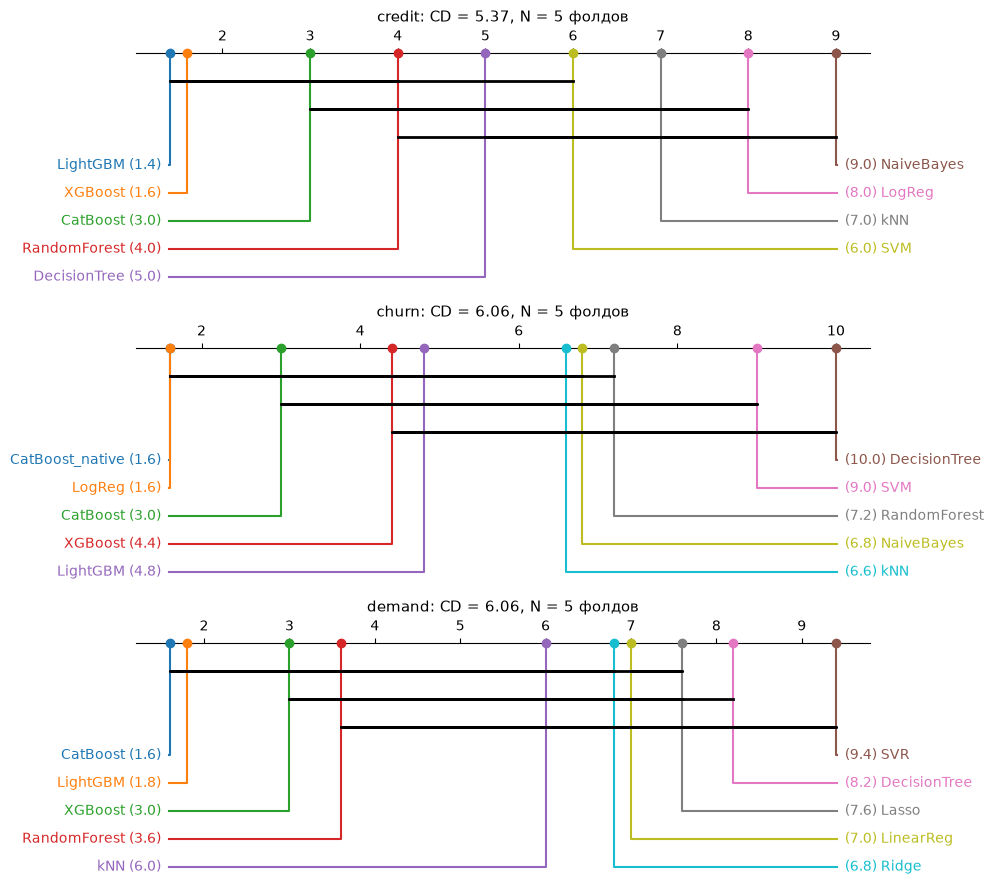

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
for ax, (ds, res) in zip(axes, per_dataset.items()):
    sp.critical_difference_diagram(res['mean_ranks'], res['nemenyi'], ax=ax, label_fmt_left='{label} ({rank:.1f})  ',
                                   label_fmt_right='  ({rank:.1f}) {label}')
    ax.set_title(f"{ds}: CD = {res['cd']:.2f}, N = {res['N']} фолдов", fontsize=11)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'cd_per_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

## Уровень 2. Глобально по трём датасетам (блоки = 15 пар «датасет × фолд»)

Фридману нужен **одинаковый набор моделей** на всех блоках. Общих для классификации и регрессии моделей 8:

| Общее имя | Классификация | Регрессия |
|---|---|---|
| Linear (L2) | LogReg (по умолчанию с L2-регуляризацией) | Ridge |
| DecisionTree, RandomForest, XGBoost, LightGBM, CatBoost, kNN | те же | те же |
| SVM | SVC | SVR |

NaiveBayes (нет регрессионного аналога), LinearReg и Lasso в глобальный тест не входят.

Ранги считаются **внутри каждого блока**, поэтому ROC-AUC и RMSE можно смешивать: важно только, кто на этом фолде лучше.

In [6]:
COMMON = {
    'credit': {'LogReg': 'Linear(L2)', 'SVM': 'SVM'},
    'churn':  {'LogReg': 'Linear(L2)', 'SVM': 'SVM'},
    'demand': {'Ridge': 'Linear(L2)', 'SVR': 'SVM'},
}
SHARED = ['DecisionTree', 'RandomForest', 'XGBoost', 'LightGBM', 'CatBoost', 'kNN']

blocks = []
for ds, df in frames.items():
    rename = {**COMMON[ds], **{m: m for m in SHARED}}
    sub = df[df['model'].isin(rename)].copy()
    sub['model'] = sub['model'].map(rename)
    m = sub.pivot(index='fold', columns='model', values=MAIN_METRIC[ds])
    if not HIGHER_IS_BETTER[ds]:
        m = -m
    m.index = [f'{ds}_f{i}' for i in m.index]
    blocks.append(m)

global_matrix = pd.concat(blocks)
print(global_matrix.shape)
global_res = friedman_nemenyi(global_matrix, higher_is_better=True, title='Глобально: 3 датасета × 5 фолдов')

(15, 8)
===== Глобально: 3 датасета × 5 фолдов =====
блоков N = 15, моделей k = 8
Friedman χ² = 65.911, p = 9.86e-12
Iman-Davenport F = 23.607, p = 1.67e-18
q_alpha = 3.031, CD = 2.711 (макс. возможная разница рангов = 7)

Средние ранги (1 - лучшая):
model
CatBoost        2.20
LightGBM        2.27
XGBoost         2.60
RandomForest    4.40
Linear(L2)      5.13
kNN             5.93
DecisionTree    6.60
SVM             6.87

Значимо различающихся пар (Неменьи, p < 0.05): 11 из 28
  CatBoost      лучше Linear(L2)     Δранг = 2.93, p = 0.0232
  CatBoost      лучше kNN            Δранг = 3.73, p = 0.0008
  CatBoost      лучше DecisionTree   Δранг = 4.40, p = 0.0000
  CatBoost      лучше SVM            Δранг = 4.67, p = 0.0000
  LightGBM      лучше Linear(L2)     Δранг = 2.87, p = 0.0294
  LightGBM      лучше kNN            Δранг = 3.67, p = 0.0011
  LightGBM      лучше DecisionTree   Δранг = 4.33, p = 0.0000
  LightGBM      лучше SVM            Δранг = 4.60, p = 0.0000
  XGBoost       лучше 

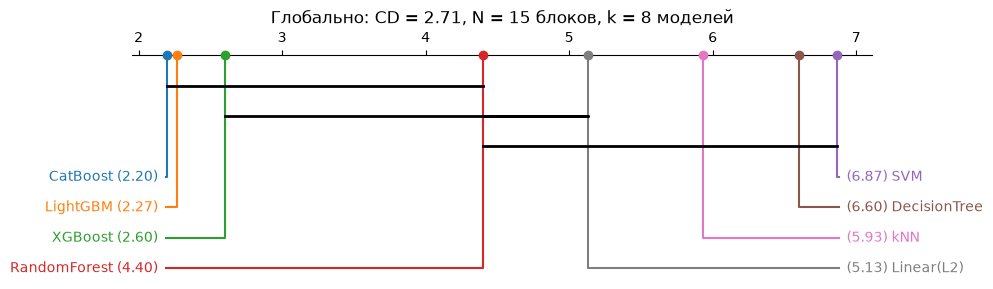

In [7]:
fig, ax = plt.subplots(figsize=(10, 3))
sp.critical_difference_diagram(global_res['mean_ranks'], global_res['nemenyi'], ax=ax,
                               label_fmt_left='{label} ({rank:.2f})  ', label_fmt_right='  ({rank:.2f}) {label}')
ax.set_title(f"Глобально: CD = {global_res['cd']:.2f}, N = {global_res['N']} блоков, k = {global_res['k']} моделей")
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'cd_global.png', dpi=150, bbox_inches='tight')
plt.show()

## Уровень 3. Классический вариант Демшара (блок = датасет, N = 3)

Так тест применяют в статьях: одна оценка (среднее по CV) на датасет. С N = 3 у теста очень мало мощности -
показываем это для честности.

In [8]:
demsar_matrix = global_matrix.groupby(global_matrix.index.str.split('_').str[0], sort=False).mean()
print(demsar_matrix.round(4))
print()
demsar_res = friedman_nemenyi(demsar_matrix, higher_is_better=True, title='Демшар: блок = датасет')

model   CatBoost  DecisionTree  LightGBM  Linear(L2)  RandomForest      SVM  \
credit    0.9406        0.9085    0.9486      0.8705        0.9301   0.8956   
churn     0.8397        0.7482    0.8331      0.8462        0.8199   0.7998   
demand   -9.1721      -10.9431   -9.2986    -10.5756       -9.6827 -12.4634   

model   XGBoost      kNN  
credit   0.9478   0.8800  
churn    0.8347   0.8224  
demand  -9.3789 -10.5109  

===== Демшар: блок = датасет =====
блоков N = 3, моделей k = 8
Friedman χ² = 13.444, p = 6.20e-02
Iman-Davenport F = 3.559, p = 2.07e-02
q_alpha = 3.031, CD = 6.062 (макс. возможная разница рангов = 7)

Средние ранги (1 - лучшая):
model
CatBoost        2.00
LightGBM        2.33
XGBoost         2.67
RandomForest    4.67
Linear(L2)      5.00
kNN             5.67
DecisionTree    6.67
SVM             7.00

Значимо различающихся пар (Неменьи, p < 0.05): 0 из 28



## Финальная таблица «метод × датасет × метрика»

Две части:

- **CV на train** (фиксированные гиперпараметры, 5 фолдов): mean ± std;
- **Тест** (гиперпараметры подобраны `RandomizedSearchCV`, одна оценка на отложенных данных).

Для классификации - ROC-AUC и F1, для регрессии - RMSE, MAE, MAPE.

In [9]:
ROW_NAME = {'LogReg': 'LogReg / Ridge', 'Ridge': 'LogReg / Ridge', 'SVM': 'SVM / SVR', 'SVR': 'SVM / SVR'}

long_rows = []
for ds, df in frames.items():
    metrics = ['roc_auc', 'f1'] if ds != 'demand' else ['rmse', 'mae', 'mape']
    for model, g in df.groupby('model'):
        for met in metrics:
            long_rows.append({'model': ROW_NAME.get(model, model), 'dataset': ds, 'metric': met, 'stage': 'cv',
                              'mean': g[met].mean(), 'std': g[met].std(ddof=0)})
    test = pd.read_csv(config.test_results(ds))
    for _, r in test.iterrows():
        for met in metrics:
            long_rows.append({'model': ROW_NAME.get(r['model'], r['model']), 'dataset': ds, 'metric': met,
                              'stage': 'test', 'mean': r[f'test_{met}'], 'std': np.nan})

final_long = pd.DataFrame(long_rows)
final_long.to_csv(config.RESULTS_DIR / 'final_table_long.csv', index=False)

ORDER = ['LogReg / Ridge', 'LinearReg', 'Lasso', 'DecisionTree', 'RandomForest', 'XGBoost', 'LightGBM',
         'CatBoost', 'CatBoost_native', 'kNN', 'SVM / SVR', 'NaiveBayes', 'Naive_lag1', 'Naive_lag7']


def fmt(r):
    return f"{r['mean']:.4f} ± {r['std']:.4f}" if r['stage'] == 'cv' else f"{r['mean']:.4f}"


final_long['value'] = final_long.apply(fmt, axis=1)
final_table = (final_long.pivot_table(index='model', columns=['dataset', 'metric', 'stage'],
                                      values='value', aggfunc='first')
               .reindex(ORDER)
               .reindex(columns=['credit', 'churn', 'demand'], level=0))
final_table.to_csv(config.final_table)

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
print("CV (mean ± std), credit / churn:")
print(final_table[['credit', 'churn']].xs('cv', axis=1, level=2).fillna('-'))

CV (mean ± std), credit / churn:
dataset                   credit                             churn                 
metric                        f1          roc_auc               f1          roc_auc
model                                                                              
LogReg / Ridge   0.6431 ± 0.0120  0.8705 ± 0.0057  0.5923 ± 0.0299  0.8462 ± 0.0126
LinearReg                      -                -                -                -
Lasso                          -                -                -                -
DecisionTree     0.8169 ± 0.0041  0.9085 ± 0.0027  0.5293 ± 0.0151  0.7482 ± 0.0126
RandomForest     0.8240 ± 0.0045  0.9301 ± 0.0022  0.5374 ± 0.0278  0.8199 ± 0.0126
XGBoost          0.8350 ± 0.0026  0.9478 ± 0.0029  0.5705 ± 0.0219  0.8347 ± 0.0082
LightGBM         0.8347 ± 0.0035  0.9486 ± 0.0013  0.5652 ± 0.0282  0.8331 ± 0.0080
CatBoost         0.8333 ± 0.0024  0.9406 ± 0.0018  0.5692 ± 0.0201  0.8397 ± 0.0101
CatBoost_native                -           

In [10]:
print("CV (mean ± std), demand:")
print(final_table['demand'].xs('cv', axis=1, level=1).fillna('-'))
print()
print("ТЕСТ после подбора гиперпараметров:")
print(final_table.xs('test', axis=1, level=2).fillna('-'))
print(f"\nСохранено: {config.final_table} и final_table_long.csv")

CV (mean ± std), demand:
metric                        mae             mape              rmse
model                                                               
LogReg / Ridge    8.1790 ± 0.3013  0.1574 ± 0.0204  10.5756 ± 0.3986
LinearReg         8.1878 ± 0.2985  0.1576 ± 0.0208  10.5866 ± 0.3950
Lasso             8.0965 ± 0.4957  0.1552 ± 0.0119  10.4693 ± 0.6264
DecisionTree      8.3432 ± 0.3842  0.1575 ± 0.0190  10.9431 ± 0.5892
RandomForest      7.4780 ± 0.3593  0.1421 ± 0.0150   9.6827 ± 0.4597
XGBoost           7.2185 ± 0.3246  0.1353 ± 0.0183   9.3789 ± 0.4292
LightGBM          7.1656 ± 0.3161  0.1345 ± 0.0170   9.2986 ± 0.4153
CatBoost          7.0834 ± 0.3189  0.1340 ± 0.0143   9.1721 ± 0.4139
CatBoost_native                 -                -                 -
kNN               8.1372 ± 0.4077  0.1537 ± 0.0185  10.5109 ± 0.5682
SVM / SVR         9.2916 ± 1.4002  0.1813 ± 0.0255  12.4634 ± 2.2537
NaiveBayes                      -                -                 -
Naive_lag

## Тепловая карта рангов

Ранг модели по основной метрике **на тесте** внутри каждого датасета (1 - лучшая). Видно, как меняется
иерархия семейств от датасета к датасету.

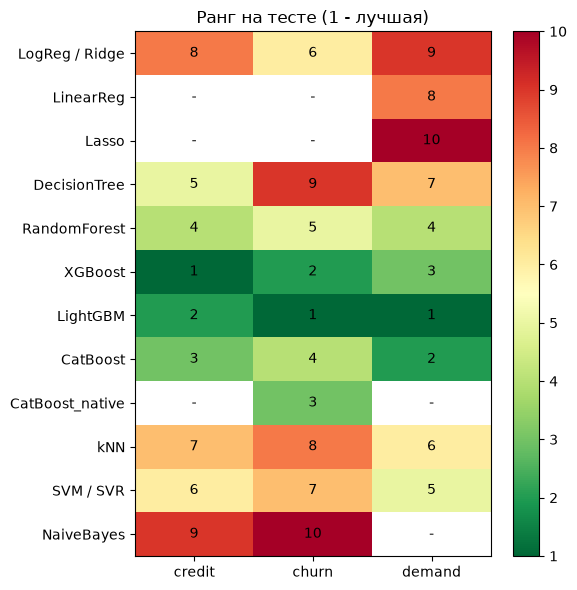

In [11]:
rank_rows = {}
for ds in ['credit', 'churn', 'demand']:
    t = pd.read_csv(config.test_results(ds)).set_index('model')
    t = t[~t.index.str.startswith('Naive_')]
    s = t[f'test_{MAIN_METRIC[ds]}']
    rank_rows[ds] = s.rank(ascending=not HIGHER_IS_BETTER[ds]).rename(index=ROW_NAME)

rank_table = pd.DataFrame(rank_rows).reindex([m for m in ORDER if not m.startswith('Naive_')]).dropna(how='all')

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(rank_table.values, cmap='RdYlGn_r', aspect='auto')
ax.set_xticks(range(rank_table.shape[1]), rank_table.columns)
ax.set_yticks(range(rank_table.shape[0]), rank_table.index)
for i in range(rank_table.shape[0]):
    for j in range(rank_table.shape[1]):
        v = rank_table.iat[i, j]
        ax.text(j, i, '-' if np.isnan(v) else f'{v:.0f}', ha='center', va='center')
ax.set_title('Ранг на тесте (1 - лучшая)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'test_rank_heatmap.png', dpi=150)
plt.show()

## Выводы

### Тест Фридмана: различия значимы на всех уровнях, кроме «блок = датасет»

| Уровень | N блоков | k моделей | p (Friedman) | CD | Значимых пар |
|---|---|---|---|---|---|
| credit (фолды) | 5 | 9 | 3.7·10⁻⁶ | 5.37 | 7 из 36 |
| churn (фолды) | 5 | 10 | 3.6·10⁻⁶ | 6.06 | 5 из 45 |
| demand (фолды) | 5 | 10 | 1.7·10⁻⁵ | 6.06 | 5 из 45 |
| глобально (датасет × фолд) | 15 | 8 | 9.9·10⁻¹² | 2.71 | 11 из 28 |
| Демшар (датасеты) | 3 | 8 | 0.062 | 6.06 | 0 из 28 |

### Глобальные средние ранги (1 - лучшая)

CatBoost 2.20, LightGBM 2.27, XGBoost 2.60, RandomForest 4.40, Linear(L2) 5.13, kNN 5.93, DecisionTree 6.60, SVM 6.87.

- **Три бустинга неразличимы между собой** (разница рангов ≤ 0.4 при CD = 2.71).
- CatBoost и LightGBM **значимо** лучше Linear(L2), kNN, DecisionTree и SVM; XGBoost - лучше kNN, DecisionTree и SVM.
- RandomForest значимо не отличается ни от бустинга, ни от линейных моделей - он посередине.

### С тремя датасетами строгий вывод невозможен

В классическом варианте Демшара (одна оценка на датасет) χ²-тест Фридмана даёт p = 0.062 (не значимо),
поправка Iman-Davenport - p = 0.021 (значимо), но CD = 6.06 при максимальной разнице рангов 7,
поэтому Неменьи не находит ни одной значимой пары. Значимость на уровне фолдов - это вывод
«внутри нашего эксперимента» (фолды зависимы), а не общий закон.

### Финальная таблица: что работает и когда

| Ситуация (по нашим данным) | Что выбрать | Основание |
|---|---|---|
| Много строк (≈ 30 тыс.), числовые признаки с порогами (credit) | XGBoost / LightGBM | тест 0.949, отрыв от RF 0.017 (> 4 SE) |
| Мало строк (≈ 6 тыс.), много категориальных (churn) | LogReg или **настроенный** бустинг | тест 0.841-0.849, разница < 1 SE; LogReg не требует подбора |
| Временной ряд с лагами (demand) | LightGBM / CatBoost | RMSE 9.4 против 11.2 у линейных и 12.9 у сезонного наивного |
| Нужна интерпретация | LogReg / Ridge | уступает лидеру 0.08 ROC-AUC на credit, ~0.01 на churn, 19% RMSE на demand |
| Без подбора гиперпараметров нельзя | DecisionTree, SVM/SVR, бустинг на малых данных | DecisionTree на churn +0.09 ROC-AUC; SVR на demand - из «хуже наивного прогноза» в 5-е место |

### Ограничения

1. 3 датасета - мало для обобщения (см. уровень Демшара).
2. Фолды CV зависимы - p-value на фолдах оптимистичны.
3. Подбор: `RandomizedSearchCV` с 6-20 итерациями на модель - бюджет ограничен 2 ядрами CPU.
4. Порог классификации не подбирался - F1 при пороге 0.5.
5. Demand: 30 пар из 500, прогноз на 1 день вперёд, без внешних факторов (промо, праздники).